# 00 — Synthèse du projet air-calib

Ce notebook résume tout le projet en une dizaine de sections : la question de départ, les données, les problèmes qu'on
a dû régler en route, les modèles, les tests de robustesse et, au bout, notre réponse.

On a essayé de garder le même fil partout : on part d'une question, on montre ce qu'on a regardé, on donne les chiffres,
puis ce qu'on en a conclu. Les passages marqués **Vérification** sont les contrôles qui nous ont évité de nous tromper
(ou qui nous ont montré qu'on se trompait).

Rien n'est recalculé ici : le notebook lit seulement les petits CSV de `reports/results/` et les figures de
`reports/figures/`, qui sont dans le dépôt. Il tourne donc en quelques secondes, sans télécharger la moindre donnée.
Pour chaque partie, on indique le notebook (01 à 07) où se trouvent le détail et le code.

## Préparation

Deux petites fonctions : `table` pour lire un fichier de résultats, `figure` pour afficher une figure déjà produite.

In [1]:
import polars as pl
from IPython.display import Image, display

from aircalib.config import get_settings

settings = get_settings()
RESULTS = settings.paths.reports_dir / "results"
FIGURES = settings.paths.reports_dir / "figures"
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_fmt_str_lengths(50)


def table(name):
    return pl.read_csv(RESULTS / f"{name}.csv")


def figure(name, width=760):
    display(Image(filename=str(FIGURES / f"{name}.png"), width=width))

## 1. La question, et pourquoi elle nous intéressait

Un capteur de particules fines grand public coûte autour de 30 €. Une station officielle, elle, coûte plusieurs
dizaines de milliers d'euros, et il n'y en a que quelques centaines par pays. Si une ville ou un assureur veut connaître
la pollution rue par rue, les stations ne suffiront jamais : il faut des capteurs bon marché. Le problème, c'est qu'ils
ne sont pas fiables tels quels.

D'où notre question : est-ce qu'on peut corriger un capteur citoyen (le **SDS011**, très répandu sur le réseau
[Sensor.Community](https://sensor.community)) pour qu'il se rapproche d'une station officielle ? Et si oui, jusqu'à
quelle distance de la station la correction tient-elle encore ?

Pour juger « se rapprocher d'une station », on a repris les cibles de l'agence américaine de l'environnement (EPA) pour
les capteurs de **PM2.5** (la masse des particules de moins de 2,5 micromètres, en µg/m³). Pour un capteur donné, on
régresse sa valeur corrigée $\hat y$ sur la valeur de la station $y$ :

$$
\hat y = s \cdot y + b
$$

avec $s$ la **pente** (elle vaut 1 si le capteur suit toute la variation de la station) et $b$ l'**ordonnée à
l'origine**, c'est-à-dire le biais quand la concentration est nulle (en µg/m³). Le capteur passe s'il tient les quatre
cibles en même temps : $R^2 \ge 0{,}70$ (la part de la variation de la station qu'il reproduit), une pente entre 0,65 et
1,35, une ordonnée entre −5 et +5 µg/m³ et une **RMSE** d'au plus 7 µg/m³ (la racine de la moyenne des carrés des
écarts capteur − station). Notre indicateur principal, c'est donc la part des capteurs qui passent les quatre cibles,
en moyennes horaires et en moyennes journalières.

## 2. Les données : quatre sources ouvertes, aucune vraiment propre

| Source | Ce qu'elle apporte | Ce qui nous a posé problème |
|---|---|---|
| Sensor.Community (archive) | les mesures brutes des capteurs citoyens, toutes les 1 à 5 minutes | 10,7 % des fichiers attendus manquants, capteurs déplacés, valeurs figées, virgules décimales, sondes d'humidité saturées |
| Agence européenne de l'environnement (EEA) | le PM2.5 horaire **vérifié** des stations officielles | une horloge mal documentée (décalée d'une heure), des manquants codés −999 |
| DWD (Allemagne), Météo-France | humidité et température officielles | fichiers à largeur fixe, un fichier par département, des stations sans humidité |

Après le nettoyage, on travaille sur des **heures-paires**. Une paire, c'est un capteur citoyen (à une position donnée)
associé à la station officielle la plus proche ; une heure-paire, c'est une heure où les deux ont une mesure valide.

In [2]:
table("volumes_gold")

country,distance_band,heures_paires,paires,stations
str,str,i64,i64,i64
"""DE""","""far""",7162545,709,187
"""DE""","""near""",5558171,577,177
"""FR""","""far""",694585,96,40
"""FR""","""near""",407051,49,35


Au total, 13,8 millions d'heures-paires sur 2024–2025. L'Allemagne sert à l'apprentissage : 577 paires à moins de
1,5 km d'une station (bande *near*) et 709 entre 1,5 et 3 km (bande *far*). La France ne sert qu'à tester le modèle :
145 paires, dix fois moins. Le détail est dans les notebooks [01](01_sources_et_faisabilite.ipynb) (faisabilité) et
[02](02_ingestion_bronze.ipynb) (téléchargement).

## 3. Le pipeline

On a rangé les données en couches successives, de plus en plus propres (ce qu'on appelle souvent une architecture
« médaillon ») :

```
Sources (≈ 1,2 million de fichiers)
  └─► raw/      fichiers téléchargés, supprimés après conversion
       └─► bronze/  Parquet, contenu inchangé + manifeste de téléchargement           (5,3 Go)
            └─► silver/  un statut par mesure, moyennes horaires UTC, paires appariées (2,7 Go)
                 └─► gold/    heures-paires utilisables + 48 variables du modèle       (1,2 Go)
                      └─► modèles, suivis dans MLflow (paramètres, métriques, prédictions)
```

Un choix qu'on a tenu du début à la fin : le nettoyage ne supprime aucune ligne. Chaque mesure garde un statut (`ok`, ou
la première règle qu'elle ne respecte pas), et le rapport `reports/funnel.md` compte ce que chaque règle a retiré. Tout le
code est dans `src/aircalib/` ; les notebooks se contentent de l'appeler et de commenter.

In [3]:
table("volumes_couches")

couche,fichiers,taille_go
str,i64,f64
"""bronze""",43724,5.3
"""silver""",1412,2.74
"""gold""",3,1.16


## 4. Cinq problèmes de données qu'on a dû régler

### 4.1 L'horloge des stations officielles avait une heure de décalage

Les métadonnées de l'EEA annoncent « UTC » pour la France et « UTC+1 » pour l'Allemagne. Plutôt que de les croire, on a
vérifié : pour chaque station, on corrèle les **variations d'une heure à l'autre** du capteur et de la station, en
décalant la station de $k$ heures. Le bon alignement est celui où la corrélation est la plus forte.

> **Vérification.** Avec notre règle `heure_UTC = Start − 1 h`, la station médiane culmine bien à $k = 0$ (figure
> ci-dessous). La contre-épreuve est parlante : sans cette correction, le test aurait rejeté 1 085 paires sur 1 142 et
> 207 stations sur 216. Sans ce contrôle, toute la France aurait été décalée d'une heure.

Détail : notebook [01](01_sources_et_faisabilite.ipynb), section 6, et notebook [03](03_nettoyage_silver.ipynb).

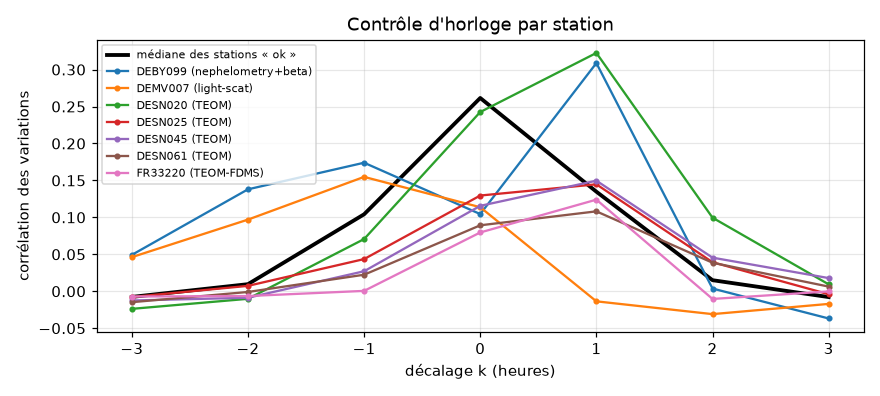

In [4]:
figure("03_horloge_stations")

La courbe noire (médiane des stations sans problème) culmine à $k = 0$ : une fois corrigés, capteur et station parlent
de la même heure. Les stations équipées d'une microbalance TEOM ont leur pic entre 0 et +1 h. Ce n'est pas une erreur
d'horloge : l'instrument répond avec environ une demi-heure de retard. On les a gardées, en ajoutant leur méthode de
mesure comme variable.

### 4.2 L'humidité des sondes bon marché est souvent fausse

L'humidité explique une grosse partie de l'erreur du capteur, parce que les particules gonflent en absorbant de l'eau.
On pensait donc utiliser la sonde d'humidité branchée sur le même boîtier. Mauvaise surprise : 53,5 % des mesures des
sondes DHT22 et 30,5 % des BME280 sont bloquées à 100 %. Et quand la sonde sature, la station météo officielle d'à côté
ne l'est que **2,1 %** du temps (avec une médiane à 85 %). Ce n'est pas du brouillard, c'est la sonde qui est en panne.

On a donc pris l'humidité **officielle** (DWD, Météo-France) comme entrée principale. La sonde locale est restée une
variable secondaire, puis on l'a retirée du modèle, puisqu'elle n'apportait rien (4,30 → 4,27 µg/m³ sans elle).

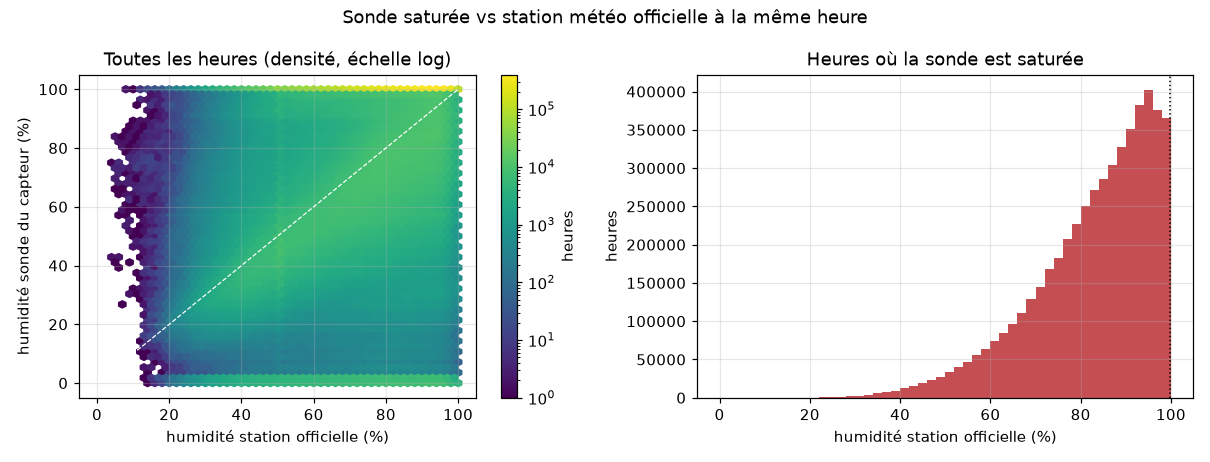

In [5]:
figure("02_saturation_vs_officiel", width=820)

Sur le graphique de droite, quand la sonde affiche 100 %, la station officielle mesure le plus souvent entre 70 et 95 %.
Si on avait gardé la sonde, on aurait mis une humidité fausse dans plus de la moitié des heures.

### 4.3 Des valeurs figées : panne, ou air très propre ?

Un capteur qui répète exactement la même valeur pendant une heure semble en panne. On a d'abord appliqué cette règle
telle quelle, puis on a regardé ce qu'elle retirait : 36,9 % des heures écartées avaient une référence sous 5 µg/m³,
contre 29,7 % pour les heures gardées. La règle visait surtout l'air propre, où un capteur qui mesure au dixième de
µg/m³ peut très bien afficher 0,3 pendant une heure.

On l'a donc resserrée : un plateau n'est considéré comme figé que s'il s'agit d'un code de panne connu (0/0), ou si la
station a varié d'au moins 5 µg/m³ pendant ce temps. Ça nous a permis de garder 12 163 plateaux d'air calme. Et on
n'a appliqué aucun filtre statistique aux particules : un pic par forte humidité, c'est justement ce que le modèle doit
apprendre à corriger.

### 4.4 Des capteurs qui déménagent (dont un depuis Hanoï)

On supposait les capteurs fixes. En réalité, 65 capteurs sur 1 399 ont changé de position pendant la période, dont 21 de
plus de 3 km. Le capteur 84804 était à Hanoï jusqu'au 5 septembre 2025 avant d'arriver à Magdebourg. On découpe donc
chaque capteur en **segments de position**, et c'est un segment (pas le capteur entier) qu'on associe à une station.
Sinon, on aurait comparé 20 mois de pollution vietnamienne à une station allemande.

### 4.5 Des capteurs qui ne suivent pas leur station

Certains capteurs ont des variations horaires qui n'ont rien à voir avec celles de leur station (corrélation médiane
des variations : 0,04). Sur les 235 paires de ce type qui ont au moins 500 heures, le $R^2$ médian est de 0,03 et aucune
ne passe les cibles EPA en horaire. Quelques-uns affichent 190 à 640 µg/m³ pour 7 à 11 µg/m³ réels, sans jamais
enfreindre une règle physique : ce sont tout simplement des capteurs défectueux. On ne les utilise jamais pour apprendre,
mais on les garde pour l'évaluation.

> **Vérification.** Tous nos résultats sont donnés deux fois : sur les **paires saines** (horloge et variations
> vérifiées) et sur **toutes les paires**, capteurs défectueux compris. Ne montrer que les saines serait trop flatteur,
> parce qu'un client ne sait pas à l'avance si son capteur est abîmé.

Pour ces cinq problèmes, le détail est dans les notebooks [02](02_ingestion_bronze.ipynb),
[03](03_nettoyage_silver.ipynb) et [04](04_exploration_paires.ipynb), et dans le journal `docs/JOURNAL.md`.

## 5. Le point de départ : un capteur sans correction

Avant de corriger quoi que ce soit, on a appliqué les cibles EPA à la mesure brute, sur toutes les paires jusqu'à 3 km.

In [6]:
table("avant").filter(pl.col("voisins") == "toutes").select(
    "pays", "paires", "paires_notees", "rmse_h", "pente_h", "epa_h", "epa_j"
)

pays,paires,paires_notees,rmse_h,pente_h,epa_h,epa_j
str,str,i64,f64,f64,f64,f64
"""DE""","""saines""",1029,9.77,0.61,23.7,38.0
"""DE""","""toutes""",1229,39.09,0.52,19.9,32.3
"""FR""","""saines""",101,7.88,0.5,15.8,24.2
"""FR""","""toutes""",136,24.45,0.43,11.8,17.9


Sans correction, 19,9 % des paires allemandes passent les cibles en horaire (32,3 % en journalier), et 11,8 % / 17,9 %
en France. C'est la pente qui coince le plus : le capteur ne voit qu'environ 60 % de la référence (pente de 0,43 à 0,61
selon le pays et les paires). Et ce rapport dépend surtout de l'humidité : 0,42 en air sec, 0,79 en air saturé, comme
on le voit ci-dessous. Détail : notebook [04](04_exploration_paires.ipynb).

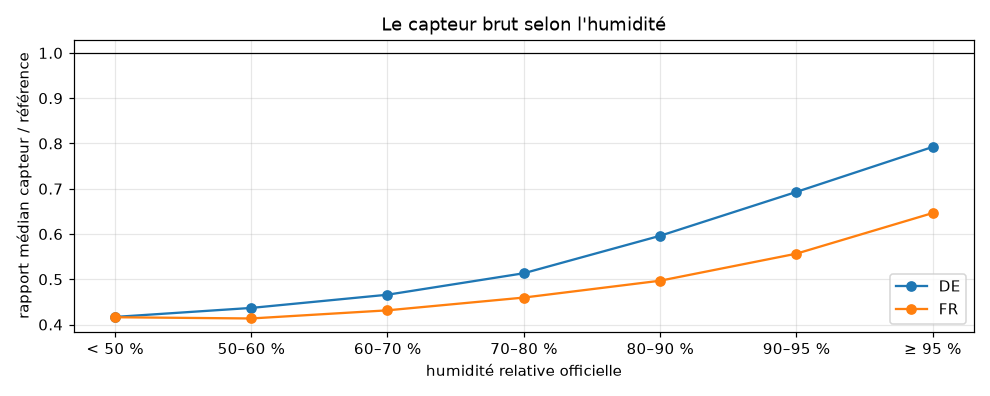

In [7]:
figure("04_rapport_humidite")

## 6. Une échelle de modèles, du plus simple au plus riche

L'idée était de trouver le modèle le plus simple qui corrige vraiment le capteur. On en a testé six, de complexité
croissante, tous évalués exactement de la même façon.

> **Vérification : le découpage par station.** Les stations allemandes sont réparties en 5 **plis** (des groupes de
> stations). Chaque modèle apprend sur 4 plis et est testé sur le 5ᵉ, et on recommence cinq fois (validation croisée).
> Une station et tous ses capteurs restent toujours dans le même pli : le modèle est donc testé sur des stations qu'il
> n'a jamais vues. Sans ça, il pourrait « reconnaître » une station déjà rencontrée et paraître meilleur qu'il n'est,
> ce qu'on appelle une **fuite d'information**.

Les modèles : **0** le capteur brut ; **1** une régression linéaire sur le logarithme ; **2** un modèle physique (un gain
plus une correction d'humidité) ; **3** **LightGBM**, un ensemble de centaines d'arbres de décision construits les uns
après les autres, chacun corrigeant les erreurs des précédents, avec 48 variables ; **4** un hybride (LightGBM qui
corrige le modèle physique) ; **5** une régression par quantiles. Et enfin le modèle **retenu** : LightGBM en µg/m³, 45
variables, réglé avec Optuna.

In [8]:
ladder = table("echelle_de_modeles")
ladder.filter((pl.col("paires") == "saines") & (pl.col("voisins") == "toutes")).select(
    "modele", "rmse_h", "r2_h", "pente_h", "epa_h", "epa_j"
)

modele,rmse_h,r2_h,pente_h,epa_h,epa_j
str,f64,f64,f64,f64,f64
"""0. capteur brut""",11.03,0.18,0.62,24.8,39.1
"""1. linéaire en log""",6.03,0.4,0.48,11.8,20.3
"""2. modèle physique""",19.47,0.16,1.11,26.4,35.2
"""3. LightGBM""",3.95,0.74,0.81,76.7,85.6
"""4. hybride""",4.0,0.74,0.82,78.0,84.4
"""5. quantiles""",3.95,0.74,0.77,73.6,83.3
"""retenu, réglages par défaut""",3.91,0.75,0.81,77.3,85.3
"""retenu, réglages Optuna""",3.84,0.76,0.82,79.7,85.3


Le modèle retenu fait passer les capteurs sains de **24,8 % à 79,7 %** des cibles EPA en horaire, et de **39,1 % à
85,3 %** en journalier. Son RMSE horaire tombe de 11,0 à 3,8 µg/m³. Les modèles simples ne suffisent pas : la régression
linéaire réduit l'erreur mais « tasse » ses prédictions vers la moyenne (pente 0,48), et le modèle physique amplifie les
pics parasites du capteur (RMSE 19,5). L'hybride fait aussi bien sur les capteurs sains mais s'effondre sur les capteurs
abîmés (RMSE 6,5 sur toutes les paires), donc on l'a écarté.

Attention, le $R^2$ du tableau est un $R^2$ *regroupé* : une seule régression sur 4,7 millions d'heures de 459
capteurs. Il passe de 0,18 à 0,76, mais il est écrasé par les écarts de niveau entre sites. Le $R^2$ médian **par
capteur**, qui est celui qu'on peut comparer aux études menées sur un seul site, passe de **0,68 à 0,87** :

In [9]:
table("r2_par_paire").filter(pl.col("paires") == "saines").select(
    "zone", "modele", "pairs", "r2_q25", "r2_median", "r2_q75", "slope_median", "rmse_median"
)

zone,modele,pairs,r2_q25,r2_median,r2_q75,slope_median,rmse_median
str,str,f64,f64,f64,f64,f64,f64
"""DE ≤ 1,5 km (5 plis)""","""brut""",459.0,0.512,0.68,0.769,0.607,6.384
"""DE ≤ 1,5 km (5 plis)""","""corrigé""",459.0,0.797,0.869,0.914,0.851,3.102
"""FR (transfert)""","""brut""",101.0,0.477,0.65,0.74,0.509,6.368
"""FR (transfert)""","""corrigé""",101.0,0.57,0.7,0.811,0.564,4.685


En fait, chaque capteur brut suit déjà plutôt bien sa station ($R^2$ médian 0,68), mais avec un mauvais gain (pente
médiane 0,61). La correction joue surtout sur le gain et le biais : pente médiane 0,85, RMSE médian 3,1 µg/m³.

> **Vérification : pente et $R^2$.** Un modèle qui minimise l'erreur quadratique a tendance à resserrer ses prédictions,
> et sa pente EPA finit à peu près égale à son $R^2$ (on le démontre dans le notebook 06). On a essayé de recalibrer la
> pente à 1 : le RMSE augmentait de 19 % et la part de capteurs dans les cibles en journalier baissait de 82 à 76 %. On a
> abandonné l'idée.

Détail : notebook [06](06_modeles.ipynb).

## 7. Ce qui fait vraiment la différence : les variables, pas le réglage

On voulait savoir d'où venait la performance : des données et des variables, ou du réglage fin du modèle ? Pour le
savoir, on a fait une **ablation** : on retire une famille de variables à la fois et on regarde de combien l'erreur
augmente. On compare ensuite avec ce que rapporte le réglage automatique des hyperparamètres (Optuna).

In [10]:
table("ablation").select("effet", "rmse_h", "delta_pct", "epa_h", "rmse_h_sans_voisins")

effet,rmse_h,delta_pct,epa_h,rmse_h_sans_voisins
str,f64,f64,f64,f64
"""sans : voisinage citoyen""",5.189,20.7,54.7,5.67
"""sans : dynamique (passé)""",4.47,4.0,68.4,6.087
"""sans : temps""",4.407,2.5,69.5,5.878
"""sans : météo officielle""",4.357,1.3,70.5,5.661
"""sans : capteur brut""",4.347,1.1,68.4,5.815
"""modèle complet""",4.301,0.0,70.5,5.77
"""sans : contexte""",4.3,-0.0,68.4,5.755
"""sans : modèle physique""",4.298,-0.1,70.5,5.766
"""sans : sonde locale (secondaire)""",4.273,-0.6,71.6,5.713


Retirer la **médiane des capteurs citoyens voisins** (dans un rayon de 3 km) fait grimper l'erreur de 20,7 %, et retirer
la dynamique des heures précédentes, de 4 %. Le réglage Optuna, lui, ne rapporte que 1,9 %. La performance vient donc des
données et des variables. C'est aussi là qu'est la limite : une heure sur cinq n'a pas de voisins, et le RMSE y monte à
5,2 µg/m³ contre 3,4 avec voisins.

> **Vérification : l'optimisme d'Optuna.** Les hyperparamètres ont été choisis sur les mêmes plis que ceux qui servent à
> l'évaluation, ce qui gonfle un peu le score. Pour mesurer ce biais, on donne aussi le modèle avec ses réglages par
> défaut : l'écart, et donc l'optimisme maximal, est de 0,07 µg/m³ (3,91 contre 3,84).

> **Vérification : quel changement a coûté quoi.** Le modèle retenu faisait un peu moins bien que l'échelon 3 sur les
> capteurs abîmés. On a appliqué ses trois changements un par un : seul le passage à une cible en µg/m³ explique ce recul
> (4,30 → 4,46 µg/m³ sur toutes les paires). Comme il fait gagner sur les capteurs sains (+1,3 point de cibles EPA), on
> l'a gardé, en écrivant cette limite noir sur blanc.

Détail : notebooks [06](06_modeles.ipynb) et [07](07_evaluation_finale.ipynb), section 1.

## 8. Est-ce que ça tient hors des conditions d'apprentissage ?

Jusque-là, le modèle a été évalué sur deux années mélangées, à moins de 1,5 km, en Allemagne. On l'a ensuite sorti de
ces conditions de trois façons, toujours sur des stations jamais vues (sauf dans le cas « mêmes stations ») :

- dans le **temps** : appris sur 2024, testé sur 2025 ;
- avec la **distance** : des capteurs jusqu'à 3 km de leur station ;
- dans un autre pays : le modèle allemand appliqué tel quel à la **France**.

Le tableau donne la part des capteurs sains qui passent les cibles EPA, en horaire puis en journalier.

In [11]:
def row(frame, label, **filters):
    part = frame.filter(pl.col("paires") == "saines")
    for column, value in filters.items():
        part = part.filter(pl.col(column) == value)
    pick = {
        v: part.filter(pl.col("voisins") == v).row(0, named=True)
        for v in ("toutes", "avec_voisins", "sans_voisins")
    }
    return {
        "test": label,
        **{f"{k} (h / j)": f"{r['epa_h']:.1f} / {r['epa_j']:.1f}" for k, r in pick.items()},
    }


temporal, dist, france = table("temporel"), table("distance"), table("france")
robustness = pl.DataFrame(
    [
        row(ladder, "référence : 5 plis, ≤ 1,5 km, 2024–2025", modele="retenu, réglages Optuna"),
        row(
            temporal, "temps : nouvelles stations, 2024 → 2025", modele="b : nouvelles stations, 2024 → 2025"
        ),
        row(
            temporal,
            "témoin : nouvelles stations, 2025 → 2025",
            modele="b0 témoin : nouvelles stations, 2025 → 2025",
        ),
        row(temporal, "temps : mêmes stations, 2024 → 2025", modele="a : mêmes stations, 2024 → 2025"),
        row(dist, "distance < 0,5 km", modele="corrigé", distance="0. < 0.5 km"),
        row(dist, "distance 2–3 km", modele="corrigé", distance="4. ≥ 2 km"),
        row(france, "France, sans réajustement", modele="corrigé", bande="toutes"),
        row(france, "France, capteur brut", modele="brut", bande="toutes"),
    ]
)
robustness

test,toutes (h / j),avec_voisins (h / j),sans_voisins (h / j)
str,str,str,str
"""référence : 5 plis, ≤ 1,5 km, 2024–2025""","""79.7 / 85.3""","""88.3 / 92.0""","""42.1 / 58.6"""
"""temps : nouvelles stations, 2024 → 2025""","""69.5 / 81.2""","""79.0 / 89.0""","""38.9 / 52.3"""
"""témoin : nouvelles stations, 2025 → 2025""","""84.3 / 88.9""","""92.0 / 93.2""","""55.8 / 69.8"""
"""temps : mêmes stations, 2024 → 2025""","""82.0 / 92.1""","""89.2 / 96.3""","""60.0 / 75.3"""
"""distance < 0,5 km""","""81.7 / 88.3""","""87.4 / 90.9""","""50.0 / 66.7"""
"""distance 2–3 km""","""70.1 / 80.1""","""81.2 / 91.3""","""49.2 / 60.0"""
"""France, sans réajustement""","""22.8 / 35.2""","""50.0 / 52.9""","""12.7 / 24.2"""
"""France, capteur brut""","""15.8 / 24.2""","""28.9 / 47.1""","""11.4 / 15.2"""


- **Le temps.** Appliqué à de nouvelles stations l'année suivante, le modèle perd 15 points en horaire (69,5 % contre
  84,3 % pour le témoin).

  > **Vérification : le témoin.** Le témoin apprend et teste sur 2025, sur les mêmes heures de test et avec à peu près
  > autant de données d'apprentissage. L'écart mesure donc l'effet du temps, et pas un simple manque de données.

  Sur les **mêmes stations**, en revanche, le modèle de 2024 tient en 2025 (82,0 % en horaire, 92,1 % en journalier).
  Conclusion pratique : il faudrait le réentraîner chaque année.
- **La distance.** Jusqu'à 3 km, elle compte peu : 81,7 % sous 0,5 km, 70,1 % entre 2 et 3 km. Le recul vient surtout
  des heures sans voisins, plus fréquentes loin des stations (38 % contre 15 %). Avec des voisins, 81 à 92 % des
  capteurs passent, quelle que soit la distance (figure).
- **La France.** Là, ça ne marche pas : 22,8 % en horaire contre 15,8 % pour le brut. 61 % des heures françaises n'ont
  pas de voisins, et les instruments de référence ne sont pas les mêmes. Il faudrait une calibration locale.

Détail : notebook [07](07_evaluation_finale.ipynb).

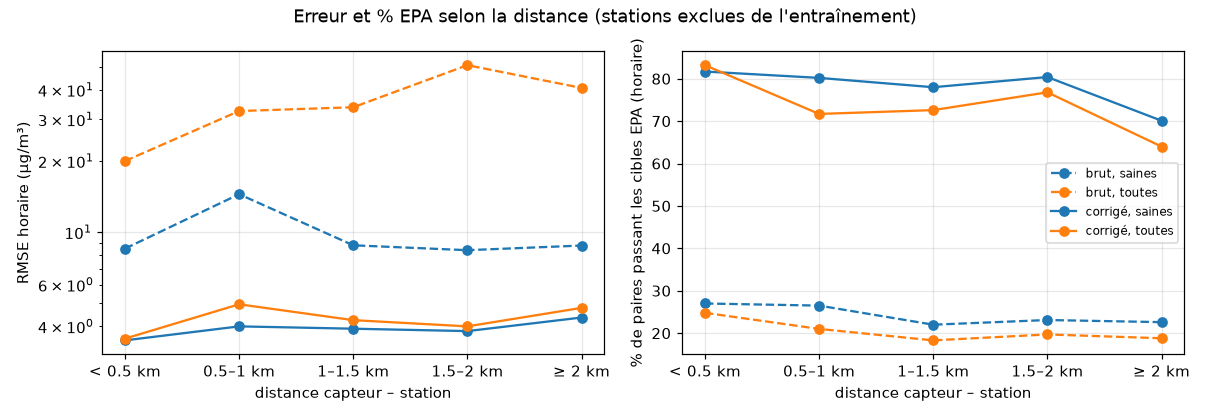

In [12]:
figure("07_distance", width=860)

Les traits pleins (capteur corrigé) restent entre 70 et 82 % de capteurs sains dans les cibles jusqu'à 3 km (64 à 83 %
sur toutes les paires), alors que les pointillés (capteur brut) ne dépassent pas 27 %. À gauche, l'erreur corrigée (en
échelle logarithmique) bouge peu avec la distance.

> **Vérification : l'intervalle de confiance.** Le modèle par quantiles annonçait un intervalle « à 80 % » qui ne
> contenait la vraie valeur que 62 % du temps. Avec une **prédiction conforme** (on élargit l'intervalle d'après les
> erreurs mesurées sur les autres plis), la couverture remonte à 79,7 % avec voisins et 79,6 % sans, vérifiée pli par
> pli (notebook 07, section 7).

## 9. Notre réponse à la question

**Oui : corrigé par un modèle appris sur d'autres stations, un capteur SDS011 en bon état passe les cibles de l'EPA
dans 80 % des cas en horaire et 85 % en journalier (contre 25 % et 39 % sans correction), et cela tient jusqu'à 3 km
d'une station (70 à 82 % selon la distance ; 81 à 92 % quand le capteur a au moins 3 voisins citoyens).** La vraie
limite est la densité du réseau citoyen, puis le temps : sans voisins, moins d'un capteur sur deux passe ; sur les
mêmes stations, le modèle appris en 2024 tient en 2025 (82 % en horaire), mais appliqué à de nouvelles stations
l'année suivante il perd 15 points, d'où un réapprentissage annuel. Le modèle allemand ne se transpose pas tel quel en
France (23 % des capteurs sains en horaire, 35 % en journalier), où 61 % des heures n'ont pas de voisins : il y faut une
calibration locale.

Pour donner un ordre de grandeur, l'étude d'Oslo sur le même capteur (Liu et al., 2019) passe d'un $R^2$ de 0,55–0,71 à
0,76–0,80, avec trois capteurs testés **sur le site même** de la station. Nous passons de 0,68 à 0,87 ($R^2$ médian
par capteur), sur des stations que le modèle n'a **jamais vues** pendant l'apprentissage.

## 10. Ce qui reste à faire

Ce qu'on n'a pas résolu, et ce que ça coûte :

1. **Les heures sans voisins citoyens** (21 % en Allemagne, 61 % en France) restent sous les cibles : seuls 42 % des
   capteurs sains passent en horaire.
2. **Le temps** : sans réapprentissage, on perd 15 points l'année suivante sur de nouvelles stations.
3. **Quelques points faibles** : les stations industrielles (aucune des 8 paires ne passe en horaire), les stations TEOM
   en horaire (55 %, mais 91 % en journalier) et le brouillard (69 % au-delà de 95 % d'humidité).
4. **Les capteurs abîmés** : la cible en µg/m³ les corrige un peu moins bien qu'une cible en log (+0,15 µg/m³ sur toutes
   les paires), et notre score de santé, qui les repère grâce à leurs voisins, n'en trouve que 56 % (avec 65 % d'alertes
   justes).
5. **L'optimisme** du chiffre de référence, dû au réglage sur les mêmes plis : 0,07 µg/m³ au maximum.
6. **Le périmètre** : SDS011 uniquement, Allemagne et France, 2024–2025, jusqu'à 3 km.

Si on devait continuer, on commencerait par une calibration locale avec quelques stations françaises, un
réapprentissage annuel, un modèle dédié aux heures sans voisins, et l'utilisation du réseau citoyen complet comme
voisinage (on n'a utilisé que les capteurs téléchargés pour ce projet).

Toutes les preuves sont dans les notebooks [01](01_sources_et_faisabilite.ipynb) à [07](07_evaluation_finale.ipynb),
dans le journal des problèmes et décisions (`docs/JOURNAL.md`) et dans le plan (`docs/PLAN.md`).

## Ce qu'il faut retenir

- Une fois corrigé, un capteur à 30 € en bon état passe les cibles EPA dans **79,7 %** des cas en horaire (24,8 % sans
  correction) et **85,3 %** en journalier (39,1 %), sur des stations jamais vues.
- Ce sont les **capteurs voisins** qui font la différence (+20,7 % d'erreur sans eux), bien plus que le réglage du modèle
  (−1,9 %).
- La correction tient **jusqu'à 3 km** (70 à 82 %) ; la vraie limite, c'est la densité du réseau citoyen.
- Sur de **nouvelles stations l'année suivante**, on perd 15 points : il faut réentraîner chaque année.
- En **France**, sans réajustement, seulement 22,8 % : une calibration locale serait nécessaire.